# Chapter 6 — Statistical Machine Learning

**Book:** Practical Statistics for Data Scientists, 2nd Edition

**Name:** Rainaldi Pakpahan
**NIM:** 101032300084
**Class:** TK 47-04

**Name:** Firdaus Arif Ramadhani
**NIM:** 101032300131
**Class:** TK 47-04

Notebook ini mengikuti urutan topik utama Chapter 6 dalam buku karya Peter Bruce, Andrew Bruce, dan Peter Gedeck. Penjelasan diberikan per subtopik secara terperinci. Notebook terdiri dari dua bagian:

- **Bagian A** mereproduksi contoh utama buku memakai data pinjaman (Lending Club) dari repository resmi buku. Bagian ini mengunduh data dari GitHub.
- **Bagian B** memakai dataset yang tersedia dalam scikit-learn sebagai contoh tambahan, sehingga dapat dijalankan di Google Colab tanpa unduhan data eksternal.

Hasil numerik dapat sedikit berbeda sesuai versi pustaka.

## Bagian A — Reproduksi Contoh Buku (Data Pinjaman)

Bagian ini mereproduksi contoh utama Chapter 6 memakai data pinjaman Lending Club dari repository resmi buku. Tiga dataset dipakai:

- `loan200.csv`: 200 pinjaman dengan dua prediktor (`payment_inc_ratio` dan `dti`) ditambah satu pinjaman baru yang akan diklasifikasikan. Dipakai untuk contoh KNN yang kecil.
- `loan3000.csv`: sampel 3,000 pinjaman dengan dua prediktor (`borrower_score` dan `payment_inc_ratio`). Dipakai untuk pohon keputusan, random forest, dan XGBoost sederhana.
- `loan_data.csv.gz`: 45,342 pinjaman dengan jumlah `paid off` dan `default` yang sama banyak. Dipakai untuk standardisasi, KNN sebagai feature engine, variable importance, regularisasi, dan validasi silang.

Target klasifikasinya adalah apakah sebuah pinjaman gagal bayar (`default`) atau lunas (`paid off`).

In [1]:
from pathlib import Path
import subprocess
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from xgboost import XGBClassifier

REPO_DIR = Path("/content/practical-statistics-for-data-scientists")
REPO_URL = "https://github.com/gedeck/practical-statistics-for-data-scientists.git"

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True
    )

DATA_DIR = REPO_DIR / "data"

loan200 = pd.read_csv(DATA_DIR / "loan200.csv")
loan3000 = pd.read_csv(DATA_DIR / "loan3000.csv")
loan_data = pd.read_csv(DATA_DIR / "loan_data.csv.gz").drop(columns=["Unnamed: 0", "status"])

print("loan200   :", loan200.shape)
print("loan3000  :", loan3000.shape)
print("loan_data :", loan_data.shape)

loan200   : (201, 3)
loan3000  : (3000, 6)
loan_data : (45342, 19)


### A.1 K-Nearest Neighbors: Contoh Kecil

KNN mengklasifikasikan sebuah pinjaman baru dengan melihat K pinjaman yang paling mirip, yaitu yang jaraknya paling dekat pada ruang prediktor, lalu mengambil suara mayoritas. Pada `loan200`, baris pertama adalah pinjaman baru (outcome `target`) dan 200 baris lainnya adalah data latih. Dua prediktor yang dipakai adalah `payment_inc_ratio` dan `dti`, dengan K = 20.

In [2]:
predictors = ["payment_inc_ratio", "dti"]

new_loan = loan200.loc[0:0, predictors]
X_small = loan200.loc[1:, predictors]
y_small = loan200.loc[1:, "outcome"]

knn_small = KNeighborsClassifier(n_neighbors=20)
knn_small.fit(X_small, y_small)

distances, neighbor_index = knn_small.kneighbors(new_loan)
neighbors = loan200.loc[1:].iloc[neighbor_index[0]]

print("Pinjaman baru            :", new_loan.iloc[0].to_dict())
print("Kelas prediksi           :", knn_small.predict(new_loan)[0])
print(pd.DataFrame(knn_small.predict_proba(new_loan), columns=knn_small.classes_).round(3))
print("\nKomposisi 20 tetangga    :", neighbors["outcome"].value_counts().to_dict())
print(f"Jarak ke tetangga terjauh: {distances.max():.3f}")

Pinjaman baru            : {'payment_inc_ratio': 9.0, 'dti': 22.5}
Kelas prediksi           : paid off
   default  paid off
0     0.45      0.55

Komposisi 20 tetangga    : {'paid off': 11, 'default': 9}
Jarak ke tetangga terjauh: 3.541


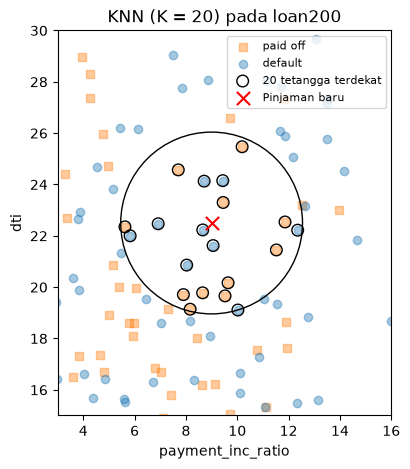

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))

for outcome, marker, color in [("paid off", "s", "tab:orange"), ("default", "o", "tab:blue")]:
    subset = loan200[loan200["outcome"] == outcome]
    ax.scatter(
        subset["payment_inc_ratio"], subset["dti"],
        marker=marker, color=color, alpha=0.4, label=outcome
    )

ax.scatter(
    neighbors["payment_inc_ratio"], neighbors["dti"],
    facecolors="none", edgecolors="black", s=70, label="20 tetangga terdekat"
)
ax.scatter(*new_loan.iloc[0], marker="x", color="red", s=90, label="Pinjaman baru")

ax.add_patch(Ellipse(
    xy=new_loan.iloc[0].to_numpy(),
    width=2 * distances.max(),
    height=2 * distances.max(),
    edgecolor="black",
    fc="none",
    lw=1
))

ax.set_xlim(3, 16)
ax.set_ylim(15, 30)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("payment_inc_ratio")
ax.set_ylabel("dti")
ax.set_title("KNN (K = 20) pada loan200")
ax.legend(fontsize=8)

plt.show()

**Interpretasi hasil:** Dari 20 pinjaman yang paling dekat dengan pinjaman baru (di dalam lingkaran pada gambar), 11 berstatus `paid off` dan 9 `default`, sehingga KNN memprediksi `paid off` dengan probabilitas 0.55 (`default` 0.45). Selisih suara yang tipis menunjukkan bahwa pinjaman baru berada di daerah yang bercampur. Hasil ini sama dengan contoh buku.

Jarak ke tetangga terjauh adalah 3.541 (dalam satuan prediktor asli) dan menentukan jari-jari lingkaran. Pemilihan K memengaruhi hasil: K yang kecil lebih sensitif terhadap noise, sedangkan K yang besar menghaluskan batas keputusan.

### A.2 Standardization: Pengaruh pada Tetangga Terdekat

Jarak pada KNN dipengaruhi satuan setiap prediktor. Contoh buku memakai empat prediktor pada `loan_data`: `payment_inc_ratio`, `dti`, `revol_bal`, dan `revol_util`. Tetangga terdekat dari pinjaman pertama dicari tanpa standardisasi lalu dengan standardisasi (z-score). Parameter scaler dihitung dari data latih.

In [4]:
predictors = ["payment_inc_ratio", "dti", "revol_bal", "revol_util"]

new_loan = loan_data.loc[0:0, predictors]
X_loan = loan_data.loc[1:, predictors]
y_loan = loan_data.loc[1:, "outcome"]

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_loan, y_loan)
raw_index = knn_raw.kneighbors(new_loan)[1][0]

scaler = StandardScaler().fit(X_loan * 1.0)
knn_std = KNeighborsClassifier(n_neighbors=5).fit(scaler.transform(X_loan * 1.0), y_loan)
std_index = knn_std.kneighbors(scaler.transform(new_loan * 1.0))[1][0]

print("Simpangan baku setiap prediktor:")
print(X_loan.std().round(1).to_string())

print("\nPinjaman baru:")
print(new_loan.round(3).to_string(index=False))

print("\n5 tetangga tanpa standardisasi:")
print(X_loan.iloc[raw_index].round(3).to_string())

print("\n5 tetangga dengan standardisasi:")
print(X_loan.iloc[std_index].round(3).to_string())

Simpangan baku setiap prediktor:
payment_inc_ratio        4.3
dti                      7.6
revol_bal            20082.7
revol_util              25.4

Pinjaman baru:
 payment_inc_ratio  dti  revol_bal  revol_util
             2.393  1.0       1687         9.4

5 tetangga tanpa standardisasi:
       payment_inc_ratio   dti  revol_bal  revol_util
35536              1.472  1.46       1686        10.0
33651              3.382  6.37       1688         8.4
25863              2.363  1.39       1691         3.5
42953              1.282  7.14       1684         3.9
43599              4.122  8.98       1684         7.2

5 tetangga dengan standardisasi:
       payment_inc_ratio   dti  revol_bal  revol_util
2080               2.611  1.03       1218         9.7
1438               2.343  0.51        278         9.9
30215              2.712  1.34       1075         8.5
28542              2.398  0.74       2917         7.4
44737              2.343  1.37        488         7.2


**Interpretasi hasil:** Prediktor `revol_bal` memiliki simpangan baku 20,082.7, jauh lebih besar daripada `payment_inc_ratio` (4.3), `dti` (7.6), dan `revol_util` (25.4). Tanpa standardisasi, jarak Euclidean hampir seluruhnya ditentukan oleh `revol_bal`: kelima tetangga memiliki `revol_bal` 1,684 sampai 1,691 (dekat dengan 1,687 milik pinjaman baru), padahal `dti` mereka 1.39 sampai 8.98 dan `payment_inc_ratio` 1.28 sampai 4.12, tidak mirip dengan pinjaman baru (`dti` 1.0 dan `payment_inc_ratio` 2.393).

Setelah standardisasi, setiap prediktor berkontribusi sebanding. Tetangga kini memiliki `payment_inc_ratio` 2.34 sampai 2.71 dan `dti` 0.51 sampai 1.37, jauh lebih mirip dengan pinjaman baru, sedangkan `revol_bal` menjadi bervariasi (278 sampai 2,917) karena tidak lagi mendominasi. Hasil ini sama dengan contoh buku. Karena tetangga berubah, prediksi KNN juga dapat berubah; standardisasi perlu dilakukan sebelum mencari tetangga.

### A.3 KNN sebagai Feature Engine

KNN juga dapat dipakai untuk membuat fitur baru. Probabilitas `paid off` dari KNN (K = 20) pada enam prediktor riwayat kredit dijadikan skor peminjam (`borrower_score`) yang kemudian dipakai sebagai prediktor pada model lain, misalnya pada Chapter 5 dan pada bagian berikut. Skor yang dihitung di sini dibandingkan dengan kolom `borrower_score` yang sudah ada pada dataset.

In [5]:
predictors = ["dti", "revol_bal", "revol_util", "open_acc", "delinq_2yrs_zero", "pub_rec_zero"]

X_score = loan_data[predictors]
y_score = loan_data["outcome"]
is_paid_off = (y_score == "paid off").astype(int)

knn_score = KNeighborsClassifier(n_neighbors=20).fit(X_score, y_score)
paid_off_column = list(knn_score.classes_).index("paid off")

borrower_score = knn_score.predict_proba(X_score)[:, paid_off_column]

print(pd.Series(borrower_score, name="borrower_score").describe().round(3).to_string())
difference = np.abs(borrower_score - loan_data["borrower_score"])

print(f"\nKorelasi dengan kolom borrower_score pada dataset: {np.corrcoef(borrower_score, loan_data['borrower_score'])[0, 1]:.4f}")
print(f"Pinjaman dengan skor identik                     : {100 * (difference < 1e-9).mean():.1f}%")
print(f"Selisih terbesar                                 : {difference.max():.2f}")

oof_score = cross_val_predict(
    KNeighborsClassifier(n_neighbors=20),
    X_score,
    y_score,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    method="predict_proba"
)[:, paid_off_column]

print(f"\nAUC skor (dihitung pada data yang sama dengan pelatihan) : {roc_auc_score(is_paid_off, borrower_score):.3f}")
print(f"AUC skor (validasi silang, tidak melihat labelnya sendiri): {roc_auc_score(is_paid_off, oof_score):.3f}")

count    45342.000
mean         0.499
std          0.129
min          0.050
25%          0.400
50%          0.500
75%          0.600
max          1.000

Korelasi dengan kolom borrower_score pada dataset: 0.9996
Pinjaman dengan skor identik                     : 99.8%
Selisih terbesar                                 : 0.15



AUC skor (dihitung pada data yang sama dengan pelatihan) : 0.657
AUC skor (validasi silang, tidak melihat labelnya sendiri): 0.545


**Interpretasi hasil:** Skor yang dihitung dengan KNN (K = 20) berkisar dari 0.05 sampai 1.00 dengan rata-rata 0.499. Skor ini sama dengan kolom `borrower_score` pada dataset untuk hampir semua pinjaman (korelasi 0.9996). Sebagian kecil pinjaman berbeda 0.05 sampai 0.15 karena beberapa tetangga memiliki jarak yang sama sehingga pemilihannya bergantung pada implementasi. Skor merangkum enam prediktor riwayat kredit menjadi satu angka yang kemudian dipakai sebagai prediktor pada model lain, misalnya regresi logistik pada Chapter 5 (Bagian A).

Ada satu hal penting. Skor yang dihitung pada data yang sama dengan pelatihan menyertakan pinjaman itu sendiri sebagai salah satu dari 20 tetangganya, sehingga skor ikut memuat informasi labelnya. Akibatnya AUC skor tampak 0.657, padahal dengan validasi silang (setiap pinjaman dinilai tanpa melihat labelnya sendiri) AUC hanya 0.545, sedikit di atas tebakan acak. Fitur turunan seperti ini sebaiknya dihitung secara out-of-fold bila akan dipakai untuk mengevaluasi model.

### A.4 Pohon Keputusan

Pohon keputusan membelah data secara rekursif berdasarkan aturan pada prediktor sehingga setiap kelompok semakin homogen. Contoh buku memakai `loan3000` dengan dua prediktor, ukuran ketidakmurnian entropy, dan `min_impurity_decrease=0.003` agar pohon tidak tumbuh terlalu besar.

In [6]:
predictors = ["borrower_score", "payment_inc_ratio"]

X_tree = loan3000[predictors]
y_tree = loan3000["outcome"]

loan_tree = DecisionTreeClassifier(random_state=1, criterion="entropy", min_impurity_decrease=0.003)
loan_tree.fit(X_tree, y_tree)

print(f"Kedalaman pohon : {loan_tree.get_depth()}")
print(f"Jumlah daun     : {loan_tree.get_n_leaves()}")
print(f"Akurasi (data latih): {loan_tree.score(X_tree, y_tree):.3f}\n")
print(export_text(loan_tree, feature_names=predictors))

Kedalaman pohon : 3
Jumlah daun     : 6
Akurasi (data latih): 0.611

|--- borrower_score <= 0.58
|   |--- borrower_score <= 0.33
|   |   |--- class: default
|   |--- borrower_score >  0.33
|   |   |--- payment_inc_ratio <= 10.42
|   |   |   |--- class: paid off
|   |   |--- payment_inc_ratio >  10.42
|   |   |   |--- class: default
|--- borrower_score >  0.58
|   |--- payment_inc_ratio <= 9.19
|   |   |--- borrower_score <= 0.72
|   |   |   |--- class: paid off
|   |   |--- borrower_score >  0.72
|   |   |   |--- class: paid off
|   |--- payment_inc_ratio >  9.19
|   |   |--- class: paid off



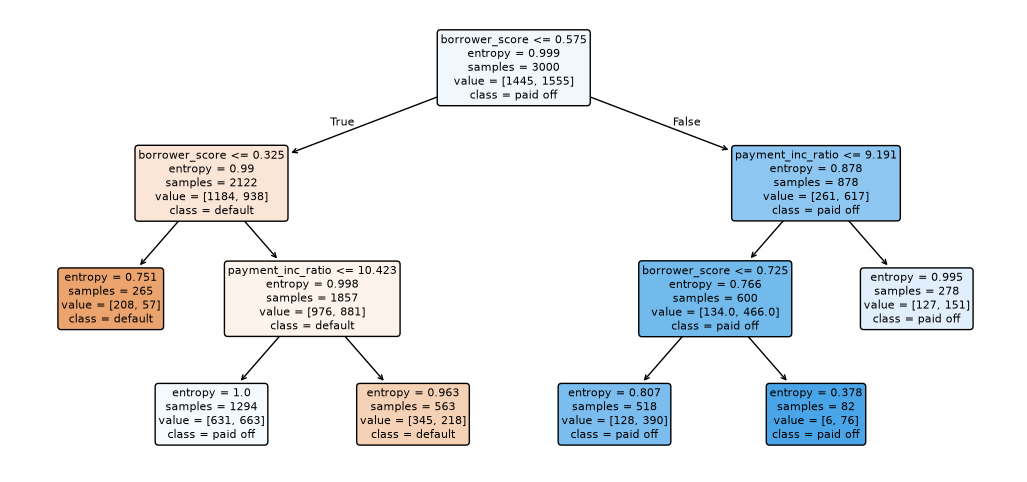

In [7]:
plt.figure(figsize=(13, 6))

plot_tree(
    loan_tree,
    feature_names=predictors,
    class_names=list(loan_tree.classes_),
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

**Interpretasi hasil:** Pohon hanya memiliki kedalaman 3 dengan 6 daun, dan akurasi pada data latih hanya 0.611, sedikit di atas tebakan, karena kedua prediktor tidak memisahkan kelas dengan baik. Aturannya mudah dibaca: bila `borrower_score` ≤ 0.58, pinjaman diprediksi `default` jika `borrower_score` ≤ 0.33 atau `payment_inc_ratio` > 10.42, dan `paid off` untuk sisanya; bila `borrower_score` > 0.58, pinjaman diprediksi `paid off` pada seluruh daun. Pembelahan pertama pada `borrower_score` (batas 0.575) menunjukkan bahwa ia adalah prediktor yang paling informatif. Struktur dan batas pohon sama dengan contoh buku.

Pada gambar, warna menunjukkan kelas mayoritas setiap node dan nilai entropy menurun menuju daun yang lebih murni, misalnya daun paling kiri (265 pinjaman, 208 di antaranya `default`, entropy 0.751) dan daun paling kanan bawah (82 pinjaman, 76 di antaranya `paid off`, entropy 0.378). Daun dengan entropy mendekati 1 (misalnya 1294 pinjaman dengan entropy 1.0) masih bercampur dan hampir tidak membedakan kelas.

### A.5 Random Forest dan Out-of-Bag (OOB)

Random forest menggabungkan banyak pohon yang dilatih pada sampel bootstrap dengan pemilihan fitur acak. Observasi yang tidak terambil pada bootstrap suatu pohon (out-of-bag) dipakai untuk menilai kinerja tanpa data uji terpisah. Pada `loan3000` dibandingkan hutan dengan pohon yang tumbuh penuh dan hutan dengan pohon dibatasi (`max_depth=5`, entropy), serta pengaruh jumlah pohon terhadap error OOB.

Pohon tumbuh penuh   | akurasi latih: 0.999 | akurasi OOB: 0.575


Pohon dibatasi (depth 5) | error OOB dengan 20 pohon: 0.387 | dengan 500 pohon: 0.387 | terendah: 0.385


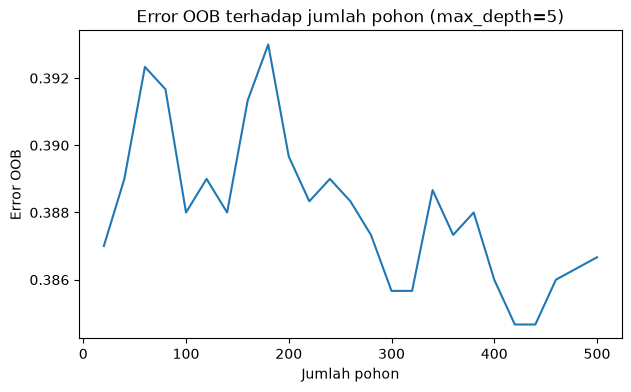

In [8]:
full_forest = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True, n_jobs=-1)
full_forest.fit(X_tree, y_tree)

print(f"Pohon tumbuh penuh   | akurasi latih: {full_forest.score(X_tree, y_tree):.3f} | akurasi OOB: {full_forest.oob_score_:.3f}")

n_trees = list(range(20, 501, 20))
oob_error = []

for n in n_trees:
    forest = RandomForestClassifier(
        n_estimators=n, criterion="entropy", max_depth=5,
        random_state=1, oob_score=True, n_jobs=-1
    )
    forest.fit(X_tree, y_tree)
    oob_error.append(1 - forest.oob_score_)

print(f"Pohon dibatasi (depth 5) | error OOB dengan 20 pohon: {oob_error[0]:.3f} | dengan 500 pohon: {oob_error[-1]:.3f} | terendah: {min(oob_error):.3f}")

plt.figure(figsize=(7, 4))
plt.plot(n_trees, oob_error)
plt.xlabel("Jumlah pohon")
plt.ylabel("Error OOB")
plt.title("Error OOB terhadap jumlah pohon (max_depth=5)")
plt.show()

**Interpretasi hasil:** Hutan dengan pohon yang tumbuh penuh menghafal data latih (akurasi latih 0.999), tetapi akurasi OOB-nya hanya 0.575, yaitu error 42.5%. Hutan dengan pohon dibatasi (`max_depth=5`) memiliki error OOB sekitar 38.7% (akurasi 0.613), lebih baik walaupun lebih sederhana, karena pohon yang terlalu dalam menyesuaikan noise.

Pada kurva, error OOB hampir datar terhadap jumlah pohon: 0.387 dengan 20 pohon dan 0.387 dengan 500 pohon, dengan fluktuasi kecil (sekitar 0.385 sampai 0.393) yang lebih mencerminkan noise pengacakan daripada perbaikan. Menambah pohon hingga beberapa ratus tidak menurunkan error secara berarti; peningkatan berikutnya harus datang dari prediktor yang lebih informatif, bukan dari lebih banyak pohon.

### A.6 Variable Importance

Random forest memberi dua ukuran pentingnya variabel. **Gini decrease** adalah rata-rata penurunan impurity akibat pembelahan pada variabel itu, dihitung saat pelatihan. **Accuracy decrease** (permutation importance) adalah penurunan akurasi pada data validasi ketika nilai variabel diacak. Contoh buku memakai 17 prediktor pada `loan_data`; variabel kategorikal diubah menjadi dummy sehingga terdapat 33 kolom. Data dibagi 70% untuk pelatihan dan 30% untuk validasi.

Kolom prediktor: 33 | akurasi validasi: 0.662

          feature  gini_decrease  accuracy_decrease  rank_gini  rank_accuracy
   borrower_score         0.0896             0.0496          7              1
            grade         0.0967             0.0277          4              2
   term_60 months         0.0202             0.0198         11              3
       annual_inc         0.0932             0.0125          5              4
payment_inc_ratio         0.1057             0.0090          1              5
        loan_amnt         0.0800             0.0041          8              6
        revol_bal         0.0930             0.0029          6              7
       revol_util         0.0979             0.0022          2              8


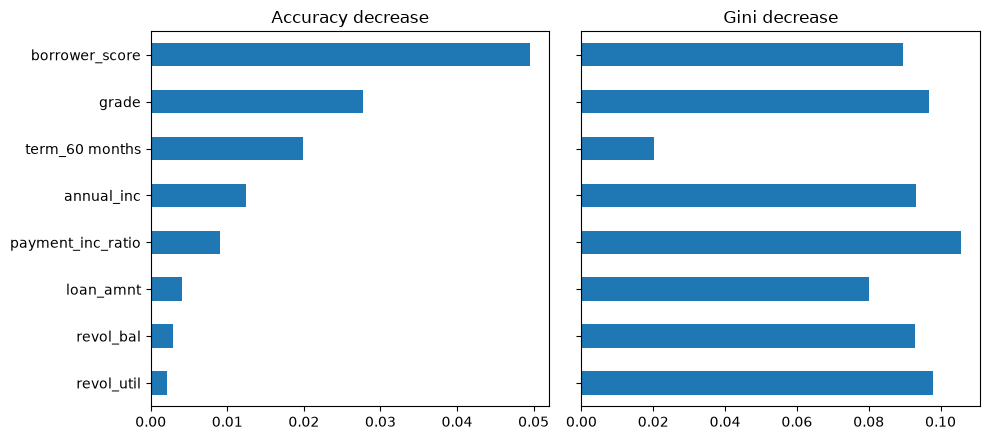

In [9]:
predictors = [
    "loan_amnt", "term", "annual_inc", "dti", "payment_inc_ratio", "revol_bal",
    "revol_util", "purpose", "delinq_2yrs_zero", "pub_rec_zero", "open_acc", "grade",
    "emp_length", "purpose_", "home_", "emp_len_", "borrower_score"
]

X_all = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
y_all = loan_data["outcome"]

X_train_all, X_valid_all, y_train_all, y_valid_all = train_test_split(
    X_all, y_all, test_size=0.3, random_state=1, stratify=y_all
)

importance_forest = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
importance_forest.fit(X_train_all, y_train_all)

permutation = permutation_importance(
    importance_forest, X_valid_all, y_valid_all,
    scoring="accuracy", n_repeats=3, random_state=1
)

importance = pd.DataFrame({
    "feature": X_all.columns,
    "gini_decrease": importance_forest.feature_importances_,
    "accuracy_decrease": permutation.importances_mean,
})
importance["rank_gini"] = importance["gini_decrease"].rank(ascending=False, method="first").astype(int)
importance["rank_accuracy"] = importance["accuracy_decrease"].rank(ascending=False, method="first").astype(int)

top = importance.sort_values("accuracy_decrease", ascending=False, kind="stable").head(8)

print(f"Kolom prediktor: {X_all.shape[1]} | akurasi validasi: {importance_forest.score(X_valid_all, y_valid_all):.3f}\n")
print(top.round(4).to_string(index=False))

fig, axes = plt.subplots(ncols=2, figsize=(10, 4.5), sharey=True)

top.iloc[::-1].plot.barh(x="feature", y="accuracy_decrease", legend=False, ax=axes[0])
axes[0].set_title("Accuracy decrease")
axes[0].set_ylabel("")

top.iloc[::-1].plot.barh(x="feature", y="gini_decrease", legend=False, ax=axes[1])
axes[1].set_title("Gini decrease")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Interpretasi hasil:** Kedua ukuran memberi gambaran yang berbeda. Menurut accuracy decrease, `borrower_score` jelas paling penting: mengacak nilainya menurunkan akurasi validasi sebesar 0.0496, jauh di atas `grade` (0.0277), `term_60 months` (0.0198), `annual_inc` (0.0125), dan `payment_inc_ratio` (0.0090). Tiga urutan teratas sejalan dengan contoh buku.

Menurut Gini decrease, `payment_inc_ratio` (0.1057) berada di peringkat pertama dan `borrower_score` hanya peringkat 7. Gini decrease cenderung memberi nilai tinggi pada variabel kontinu yang memiliki banyak titik pembelahan (seperti `payment_inc_ratio`, `revol_util`, `annual_inc`, dan `revol_bal`), sedangkan variabel biner seperti `term_60 months` tampak kecil (0.0202, peringkat 11) padahal pengaruhnya pada akurasi nyata (peringkat 3). Karena itu accuracy decrease lebih dekat dengan pertanyaan seberapa berguna suatu variabel bagi prediksi, dan Gini decrease sebaiknya dibaca dengan hati-hati.

Perlu diingat bahwa `borrower_score` adalah skor KNN yang dihitung pada data yang sama (bagian A.3), sehingga pentingnya kemungkinan terlalu optimis.

### A.7 XGBoost pada loan3000 dan Perbandingan dengan Pohon dan Random Forest

XGBoost membangun pohon secara berurutan; setiap pohon memperbaiki kesalahan ensemble sebelumnya. Contoh buku memakai `loan3000` dengan `subsample=0.63`. Karena ketiga model dilatih pada data yang sama, akurasi dibandingkan pada data latih dan pada data uji (30% dari `loan3000`) untuk melihat perbedaan kemampuan generalisasi.

In [10]:
y_binary = (loan3000["outcome"] == "default").astype(int)

X_train_small, X_test_small, y_train_small, y_test_small = train_test_split(
    X_tree, y_binary, test_size=0.3, random_state=1, stratify=y_binary
)

models = {
    "Pohon keputusan": DecisionTreeClassifier(random_state=1, criterion="entropy", min_impurity_decrease=0.003),
    "Random forest (depth 5)": RandomForestClassifier(
        n_estimators=500, criterion="entropy", max_depth=5, random_state=1, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(objective="binary:logistic", subsample=0.63, eval_metric="error", random_state=1),
}

rows = []

for name, model in models.items():
    model.fit(X_train_small, y_train_small)
    rows.append({
        "Model": name,
        "Akurasi latih": model.score(X_train_small, y_train_small),
        "Akurasi uji": model.score(X_test_small, y_test_small),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

                  Model  Akurasi latih  Akurasi uji
        Pohon keputusan          0.629        0.603
Random forest (depth 5)          0.658        0.610
                XGBoost          0.776        0.581


**Interpretasi hasil:** Semakin fleksibel modelnya, semakin besar selisih antara akurasi latih dan uji. XGBoost memiliki akurasi latih tertinggi (0.776) tetapi akurasi uji terendah (0.581), tanda overfitting. Pohon keputusan yang kecil hampir tidak overfit (0.629 dibanding 0.603), dan random forest dengan pohon dibatasi memberi akurasi uji tertinggi (0.610) dengan selisih latih-uji yang sedang (0.658 dibanding 0.610).

Perbedaan akurasi uji antarmodel (0.581 sampai 0.610) kecil karena kedua prediktor hanya sedikit informatif, dan data uji hanya 900 pinjaman sehingga selisih sekecil itu masih dalam kisaran noise. Pelajaran utamanya: model yang lebih kompleks tidak otomatis lebih baik, dan XGBoost memerlukan regularisasi serta penyetelan hyperparameter seperti pada dua bagian berikut.

### A.8 Regularisasi pada XGBoost

XGBoost memiliki beberapa pengaturan untuk membatasi kompleksitas, antara lain `reg_lambda` (penalti pada bobot daun), `learning_rate` yang lebih kecil, dan `subsample` (hanya sebagian data dipakai untuk setiap pohon). Dua model dibandingkan pada `loan_data` dengan 10,000 observasi sebagai data validasi: model tanpa regularisasi (`reg_lambda=0`, `learning_rate=0.3`) dan model dengan regularisasi (`reg_lambda=1000`, `learning_rate=0.1`, `subsample=0.63`). Error dicatat pada setiap iterasi.

Error akhir (250 iterasi)
  tanpa regularisasi | latih: 0.1090 | validasi: 0.3590
  dengan regularisasi | latih: 0.3115 | validasi: 0.3294

Error validasi terendah
  tanpa regularisasi : 0.3307 pada iterasi 12
  dengan regularisasi: 0.3278 pada iterasi 147


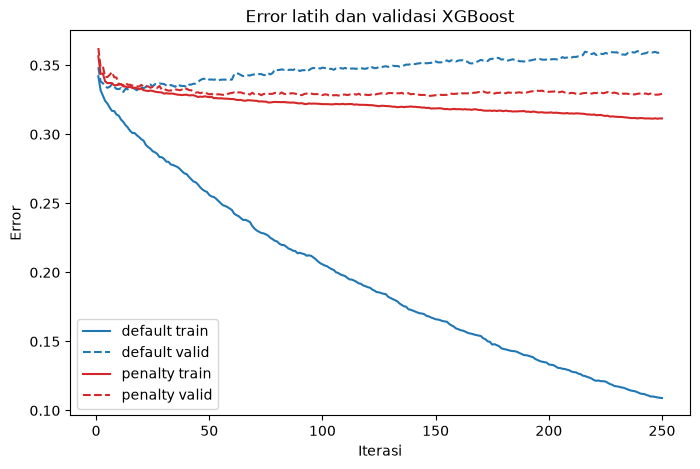

In [11]:
y_binary_all = (loan_data["outcome"] == "default").astype(int)

X_fit, X_valid, y_fit, y_valid = train_test_split(X_all, y_binary_all, test_size=10000, random_state=1)

xgb_default = XGBClassifier(
    objective="binary:logistic", n_estimators=250, max_depth=6,
    reg_lambda=0, learning_rate=0.3, subsample=1, eval_metric="error", random_state=1
)
xgb_penalty = XGBClassifier(
    objective="binary:logistic", n_estimators=250, max_depth=6,
    reg_lambda=1000, learning_rate=0.1, subsample=0.63, eval_metric="error", random_state=1
)

history = {}

for name, model in [("default", xgb_default), ("penalty", xgb_penalty)]:
    model.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_valid, y_valid)], verbose=False)
    result = model.evals_result()
    history[f"{name} train"] = result["validation_0"]["error"]
    history[f"{name} valid"] = result["validation_1"]["error"]

history = pd.DataFrame(history, index=range(1, 251))

print("Error akhir (250 iterasi)")
print(f"  tanpa regularisasi | latih: {history['default train'].iloc[-1]:.4f} | validasi: {history['default valid'].iloc[-1]:.4f}")
print(f"  dengan regularisasi | latih: {history['penalty train'].iloc[-1]:.4f} | validasi: {history['penalty valid'].iloc[-1]:.4f}")
print("\nError validasi terendah")
print(f"  tanpa regularisasi : {history['default valid'].min():.4f} pada iterasi {history['default valid'].idxmin()}")
print(f"  dengan regularisasi: {history['penalty valid'].min():.4f} pada iterasi {history['penalty valid'].idxmin()}")

ax = history.plot(figsize=(8, 5), style=["-", "--", "-", "--"], color=["tab:blue", "tab:blue", "tab:red", "tab:red"])
ax.set_xlabel("Iterasi")
ax.set_ylabel("Error")
ax.set_title("Error latih dan validasi XGBoost")
plt.show()

**Interpretasi hasil:** Tanpa regularisasi, error latih terus turun hingga 0.109 pada iterasi ke-250, tetapi error validasi justru naik dari titik terendahnya 0.331 (iterasi ke-12) menjadi 0.359: model menghafal data latih. Dengan regularisasi, error latih tetap tinggi (0.3115) tetapi error validasi lebih rendah dan stabil (0.329 pada akhir; terendah 0.328 pada iterasi ke-147). Selisih antara error validasi dan latih pada model dengan regularisasi (sekitar 0.02) jauh lebih kecil daripada tanpa regularisasi (sekitar 0.25).

Hasilnya sejalan dengan contoh buku (error validasi 0.361 tanpa regularisasi dan 0.333 dengan regularisasi). Regularisasi mengorbankan sedikit kemampuan mencocokkan data latih demi generalisasi yang lebih baik, dan jumlah iterasi terbaik tidak harus sama dengan jumlah iterasi maksimum.

### A.9 Hyperparameter dan Validasi Silang

Pengaturan seperti `learning_rate` (eta) dan `max_depth` dipilih dengan validasi silang. Contoh buku menguji kombinasi eta 0.1, 0.5, dan 0.9 dengan `max_depth` 3, 6, dan 9. Di sini dipakai 5-fold validasi silang dan 100 pohon untuk setiap model agar waktu eksekusi singkat; error adalah persentase pinjaman yang salah diklasifikasikan pada data validasi.

In [12]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=1).split(X_all, y_binary_all))

errors = []

for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    fold_errors = []

    for train_index, valid_index in folds:
        model = XGBClassifier(
            objective="binary:logistic", n_estimators=100, max_depth=max_depth,
            learning_rate=eta, eval_metric="error", random_state=1
        )
        model.fit(X_all.iloc[train_index], y_binary_all.iloc[train_index])
        prediction = model.predict(X_all.iloc[valid_index])
        fold_errors.append(np.mean(prediction != y_binary_all.iloc[valid_index]))

    errors.append({"eta": eta, "max_depth": max_depth, "error (%)": 100 * np.mean(fold_errors)})

errors = pd.DataFrame(errors)

print("Rata-rata error validasi silang (%):")
print(errors.pivot_table(index="eta", columns="max_depth", values="error (%)").round(2))

best = errors.loc[errors["error (%)"].idxmin()]
print(f"\nKombinasi terbaik: eta = {best['eta']}, max_depth = {int(best['max_depth'])} (error {best['error (%)']:.2f}%)")

Rata-rata error validasi silang (%):
max_depth      3      6      9
eta                           
0.1        33.04  33.24  34.04
0.5        33.40  35.36  37.32
0.9        34.26  37.94  38.47

Kombinasi terbaik: eta = 0.1, max_depth = 3 (error 33.04%)


**Interpretasi hasil:** Error validasi silang terendah diperoleh pada `eta = 0.1` dan `max_depth = 3` (33.04%). Untuk setiap eta, error naik ketika pohon semakin dalam, dan untuk setiap kedalaman, error naik ketika learning rate semakin besar, hingga 38.47% pada `eta = 0.9` dan `max_depth = 9`. Model yang lebih agresif dan lebih kompleks overfit pada data ini. Pola ini sama dengan contoh buku (terbaik pada `eta = 0.1` dan `max_depth = 3` dengan error sekitar 33%).

Selisih antara kombinasi terbaik dan beberapa kombinasi di dekatnya sangat kecil (33.04% dibanding 33.24% dan 33.40%), sehingga selisih sekecil itu belum tentu bermakna, sedangkan kombinasi yang agresif jelas lebih buruk. Setelah hyperparameter dipilih lewat validasi silang, kinerja akhir sebaiknya dikonfirmasi pada data uji yang terpisah.

## Bagian B — Contoh Tambahan (Dataset Breast Cancer, scikit-learn)

Bagian berikut memakai dataset breast cancer bawaan scikit-learn sebagai contoh tambahan. Dataset ini tersedia secara offline sehingga bagian ini dapat dijalankan tanpa unduhan data.

## Persiapan Data Statistical Machine Learning

Chapter 6 membahas algoritma prediktif yang tidak mengharuskan hubungan linear tunggal antara seluruh prediktor dan target. Kita menggunakan dataset breast cancer yang tersedia offline agar setiap algoritma dapat dibandingkan secara konsisten.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
raw=load_breast_cancer(as_frame=True)
X,y=raw.data,raw.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
print('Training:',X_train.shape,'Testing:',X_test.shape,'Target:',raw.target_names)

Training: (426, 30) Testing: (143, 30) Target: ['malignant' 'benign']


**Interpretasi:** Semua model akan dievaluasi pada pembagian data yang sama. Dengan demikian, perbedaan hasil lebih mudah dikaitkan dengan pendekatan pemodelan dan hyperparameter.

## K-Nearest Neighbors (KNN)

KNN menentukan kelas berdasarkan suara mayoritas dari K titik terdekat. Karena jarak dipengaruhi satuan fitur, standardisasi merupakan langkah penting sebelum menjalankan KNN.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train,y_train)
knn_pred=knn.predict(X_test)
print('Akurasi KNN:',round(accuracy_score(y_test,knn_pred),3))
print('Prediksi awal:',knn_pred[:12])

Akurasi KNN: 0.979
Prediksi awal: [1 0 1 1 0 0 0 0 0 1 1 1]


**Interpretasi:** Model tidak membentuk rumus global eksplisit, tetapi menggunakan kedekatan data baru dengan data latih. Nilai K yang kecil lebih sensitif pada noise, sementara K yang besar dapat menghaluskan batas keputusan.

## Distance Metrics dan Standardization

Jarak Euclidean mengukur jarak garis lurus, sedangkan Manhattan menjumlahkan selisih absolut. Dengan satuan fitur yang berbeda, pengukuran jarak tanpa standardisasi dapat menyesatkan.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [15]:
from sklearn.metrics import pairwise_distances
v = np.array([[1,2],[4,6],[2,8]])
for metric in ['euclidean','manhattan']:
 print(metric,' — ',np.round(pairwise_distances(v,metric=metric),2))
for metric in ['euclidean','manhattan']:
 model=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5,metric=metric)).fit(X_train,y_train)
 print('Accuracy',metric,round(model.score(X_test,y_test),3))

euclidean  —  [[0.   5.   6.08]
 [5.   0.   2.83]
 [6.08 2.83 0.  ]]
manhattan  —  [[0. 7. 7.]
 [7. 0. 4.]
 [7. 4. 0.]]
Accuracy euclidean 0.979
Accuracy manhattan 0.965


**Interpretasi:** Kedua metrik menghasilkan ukuran kedekatan yang berbeda. Model KNN perlu memilih metrik jarak yang sesuai dengan struktur data, bukan mengasumsikan Euclidean selalu terbaik.

## Memilih Nilai K

Nilai K dapat dipilih menggunakan cross-validation. Evaluasi dilakukan di data latih saja sehingga data uji tetap disimpan untuk evaluasi akhir.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

 K  CV_accuracy
 1        0.937
 3        0.962
 5        0.967
 7        0.965
 9        0.969
11        0.967
15        0.965
21        0.958


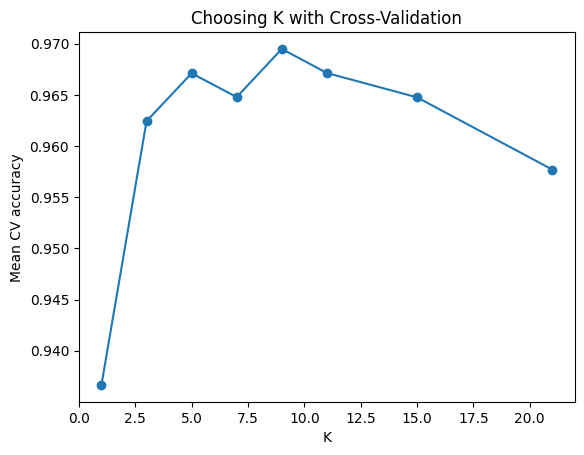

In [16]:
ks=[1,3,5,7,9,11,15,21]
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
results=[]
for k in ks:
 model=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=k))
 results.append(cross_val_score(model,X_train,y_train,cv=cv,scoring='accuracy').mean())
print(pd.DataFrame({'K':ks,'CV_accuracy':np.round(results,3)}).to_string(index=False))
plt.plot(ks,results,marker='o');plt.xlabel('K');plt.ylabel('Mean CV accuracy');plt.title('Choosing K with Cross-Validation');plt.show()

**Interpretasi:** K dengan skor validasi tertinggi menjadi kandidat, tetapi perbedaan sangat kecil tidak selalu bermakna. Cross-validation lebih dapat diandalkan daripada memilih K hanya berdasarkan satu pembagian data.

## KNN sebagai Feature Engine

Selain sebagai model prediksi, jarak ke tetangga terdekat dapat dipakai sebagai fitur baru. Fitur ini merangkum seberapa dekat sebuah observasi dengan pola yang tersedia pada data latih.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [17]:
from sklearn.neighbors import NearestNeighbors
scale=StandardScaler().fit(X_train)
tr=scale.transform(X_train); te=scale.transform(X_test)
nn=NearestNeighbors(n_neighbors=6).fit(tr)
train_dist,_=nn.kneighbors(tr)
test_dist,_=nn.kneighbors(te)
print('Rata-rata jarak ke 5 tetangga (train):',round(train_dist[:,1:].mean(),3))
print('Rata-rata jarak ke 6 tetangga (test):',round(test_dist.mean(),3))

Rata-rata jarak ke 5 tetangga (train): 2.81
Rata-rata jarak ke 6 tetangga (test): 2.793


**Interpretasi:** Data latih mempunyai jarak nol terhadap dirinya sendiri, sehingga tetangga pertama dikeluarkan dari ringkasan train. Untuk observasi uji, seluruh tetangga berasal dari data latih.

## Decision Tree

Pohon keputusan berulang kali membelah data berdasarkan aturan fitur untuk menghasilkan kelompok yang lebih homogen. Keuntungannya adalah aturan prediksi relatif mudah dipahami.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

Train accuracy: 0.974
Test accuracy: 0.944


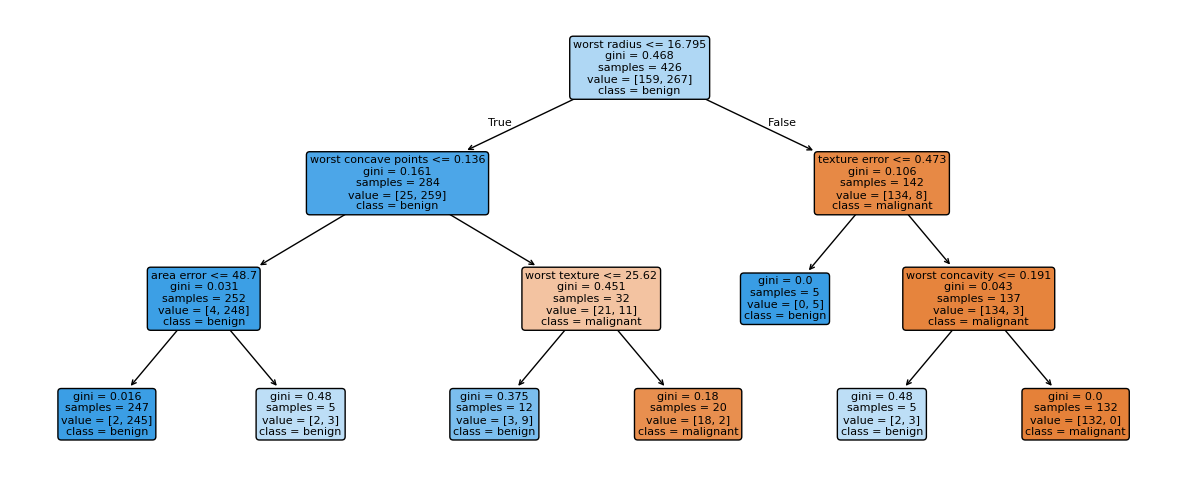

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=42).fit(X_train,y_train)
print('Train accuracy:',round(tree.score(X_train,y_train),3))
print('Test accuracy:',round(tree.score(X_test,y_test),3))
plt.figure(figsize=(15,6))
plot_tree(tree,feature_names=list(X.columns),class_names=list(raw.target_names),filled=True,rounded=True,fontsize=8)
plt.show()

**Interpretasi:** Setiap node menampilkan aturan pembelahan, jumlah sampel, dan distribusi kelas. Membatasi kedalaman dan ukuran daun mengurangi risiko pohon menghafal data latih.

## Impurity dan Pruning

Kriteria Gini dan entropy mengukur ketidakmurnian kelas pada node. Parameter `ccp_alpha` dapat memangkas pohon agar lebih sederhana.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [19]:
for criterion in ['gini','entropy']:
 for alpha in [0.0,0.003,0.01]:
  m=DecisionTreeClassifier(criterion=criterion,ccp_alpha=alpha,random_state=42).fit(X_train,y_train)
  print(f'{criterion:7s} alpha={alpha:.3f} nodes={m.tree_.node_count:3d} test_accuracy={m.score(X_test,y_test):.3f}')

gini    alpha=0.000 nodes= 35 test_accuracy=0.923
gini    alpha=0.003 nodes= 23 test_accuracy=0.937
gini    alpha=0.010 nodes=  9 test_accuracy=0.944
entropy alpha=0.000 nodes= 29 test_accuracy=0.930
entropy alpha=0.003 nodes= 29 test_accuracy=0.930
entropy alpha=0.010 nodes= 29 test_accuracy=0.930


**Interpretasi:** Nilai pruning lebih besar cenderung mengurangi jumlah node, tetapi pemangkasan berlebihan dapat menyebabkan underfitting. Pemilihan parameter sebaiknya menggunakan cross-validation.

## Bagging dan Random Forest

Bagging menggabungkan prediksi banyak model yang dilatih pada sampel bootstrap. Random forest menambahkan pengacakan fitur sehingga pohon lebih beragam.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [20]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
bag=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),n_estimators=70,random_state=42,n_jobs=-1).fit(X_train,y_train)
rf=RandomForestClassifier(n_estimators=120,min_samples_leaf=2,random_state=42,n_jobs=-1).fit(X_train,y_train)
for name,m in [('Bagging',bag),('Random Forest',rf)]:
 print(name,'train=',round(m.score(X_train,y_train),3),'test=',round(m.score(X_test,y_test),3))

Bagging train= 1.0 test= 0.958
Random Forest train= 0.993 test= 0.958


**Interpretasi:** Ensemble mengurangi variasi prediksi dari sebuah pohon tunggal. Selisih skor train-test membantu memeriksa apakah model terlalu menyesuaikan diri dengan data latih.

## Variable Importance

Random forest dapat memberikan ukuran pentingnya fitur berdasarkan rata-rata penurunan impurity. Ukuran ini bermanfaat untuk eksplorasi, tetapi dapat bias pada fitur tertentu dan tidak membuktikan sebab-akibat.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

worst area              0.1650
worst concave points    0.1147
worst perimeter         0.1047
mean concave points     0.1021
worst radius            0.0869
mean perimeter          0.0674
mean radius             0.0628
mean concavity          0.0496
mean area               0.0423
worst concavity         0.0275


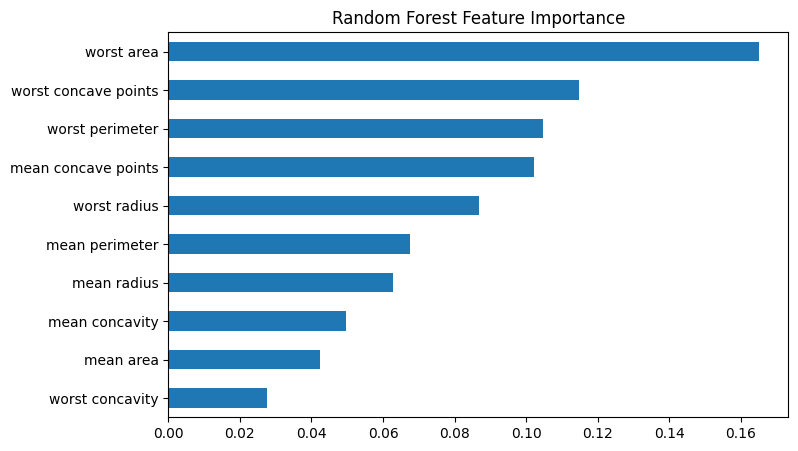

In [21]:
importance=pd.Series(rf.feature_importances_,index=X.columns).sort_values(ascending=False).head(10)
print(importance.round(4).to_string())
importance.sort_values().plot(kind='barh',figsize=(8,5),title='Random Forest Feature Importance')
plt.show()

**Interpretasi:** Fitur dengan nilai tinggi sering dipakai untuk mengurangi ketidakmurnian dalam model tersebut. Untuk analisis yang lebih kuat, pertimbangkan permutation importance di data validasi.

## Boosting

Boosting membangun model secara bertahap sehingga model berikutnya memperbaiki kesalahan sebelumnya. Contoh ini menggunakan GradientBoostingClassifier dari scikit-learn.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [22]:
from sklearn.ensemble import GradientBoostingClassifier
gb=GradientBoostingClassifier(n_estimators=100,learning_rate=0.05,max_depth=2,random_state=42).fit(X_train,y_train)
print('Gradient Boosting train accuracy:',round(gb.score(X_train,y_train),3))
print('Gradient Boosting test accuracy:',round(gb.score(X_test,y_test),3))

Gradient Boosting train accuracy: 0.995
Gradient Boosting test accuracy: 0.944


**Interpretasi:** Kombinasi learning rate, jumlah estimator, dan kedalaman pohon menentukan kekuatan model. Penambahan tahap yang terlalu banyak juga dapat meningkatkan overfitting.

## XGBoost dan Regularisasi

XGBoost merupakan implementasi boosting yang efisien dengan kontrol kompleksitas seperti regularisasi, subsampling, dan ukuran pohon. Paket `xgboost` dapat dipasang di Colab bila belum tersedia.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [23]:
try:
 from xgboost import XGBClassifier
 xgb=XGBClassifier(n_estimators=80,max_depth=3,learning_rate=0.07,subsample=0.85,colsample_bytree=0.85,eval_metric='logloss',random_state=42,n_jobs=2)
 xgb.fit(X_train,y_train)
 print('XGBoost test accuracy:',round(xgb.score(X_test,y_test),3))
except ImportError:
 print('XGBoost belum terpasang. Jalankan: %pip install xgboost')

XGBoost test accuracy: 0.965


**Interpretasi:** XGBoost menggabungkan banyak pohon secara bertahap dan menyediakan pengaturan regularisasi untuk membatasi kompleksitas. Hasil harus dinilai menggunakan data di luar pelatihan.

## Perbandingan Model dengan Cross-Validation

Satu angka akurasi pada data uji bisa dipengaruhi oleh pembagian sampel. Cross-validation pada data latih membantu membandingkan model dengan lebih stabil.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [24]:
models={'KNN':make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)),
        'Tree':DecisionTreeClassifier(max_depth=3,random_state=42),
        'Random Forest':RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1),
        'Gradient Boosting':GradientBoostingClassifier(n_estimators=80,random_state=42)}
rows=[]
for name,model in models.items():
 score=cross_val_score(model,X_train,y_train,cv=5,scoring='accuracy')
 rows.append((name,round(score.mean(),3),round(score.std(),3)))
print(pd.DataFrame(rows,columns=['Model','Mean CV Accuracy','CV Std']).to_string(index=False))

            Model  Mean CV Accuracy  CV Std
              KNN             0.962   0.016
             Tree             0.930   0.028
    Random Forest             0.960   0.021
Gradient Boosting             0.953   0.018


**Interpretasi:** Skor rata-rata menunjukkan kinerja selama validasi, sedangkan simpangan baku menunjukkan variasi antarlipatan. Model terbaik tidak hanya dilihat dari akurasi, tetapi juga stabilitas dan kebutuhan interpretasi.

## Pendalaman Subtopik sesuai Struktur Buku

Bagian berikut memperinci konsep-konsep penting yang dibahas di chapter ini. Contoh tambahan menggunakan dataset yang disiapkan pada bagian awal notebook, sehingga setiap pembahasan tetap dapat dijalankan berurutan di Google Colab.

### 1. KNN: Contoh Prediksi Dua Dimensi

KNN bekerja dengan mencari tetangga yang jaraknya paling dekat dengan titik baru. Supaya prinsip ini terlihat, kita gunakan dataset dua fitur. Algoritma tidak membangun koefisien linear seperti regresi; prediksinya bergantung pada posisi titik dalam ruang fitur dan label tetangganya.

Label lima tetangga: [0 0 0 1 0]
Kelas prediksi: 0


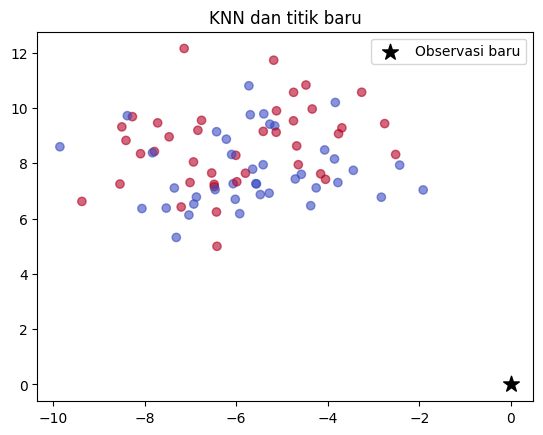

In [25]:
from sklearn.datasets import make_blobs
xb,yb=make_blobs(n_samples=80,centers=2,cluster_std=1.5,random_state=5)
kn2=KNeighborsClassifier(n_neighbors=5).fit(xb,yb)
new=np.array([[0.,0.]])
dist,ix=kn2.kneighbors(new)
print('Label lima tetangga:',yb[ix[0]])
print('Kelas prediksi:',kn2.predict(new)[0])
plt.scatter(xb[:,0],xb[:,1],c=yb,cmap='coolwarm',alpha=.6)
plt.scatter(new[:,0],new[:,1],s=140,marker='*',c='black',label='Observasi baru')
plt.legend();plt.title('KNN dan titik baru');plt.show()

**Interpretasi hasil:** Prediksi dihasilkan dari label tetangga terdekat. KNN dapat mengikuti bentuk sebaran yang rumit, tetapi hasilnya sensitif terhadap posisi titik, pilihan K, metrik jarak, dan normalisasi setiap fitur.

### 2. Minkowski, Euclidean, dan Manhattan Distance

Jarak Euclidean mengukur garis lurus antartitik, sedangkan Manhattan menjumlahkan selisih absolut tiap dimensi. Keduanya adalah kasus khusus dari jarak Minkowski, dengan parameter p=2 dan p=1. Pilihan jarak memengaruhi siapa yang dianggap sebagai tetangga terdekat, terutama ketika fitur memiliki struktur atau skala berbeda.

In [26]:
from scipy.spatial.distance import minkowski, cityblock, euclidean
a=np.array([1.,2.,3.]);b=np.array([4.,4.,8.])
print('Euclidean:',round(euclidean(a,b),3))
print('Manhattan:',round(cityblock(a,b),3))
for p in [1,2,3]:print(f'Minkowski p={p}:',round(minkowski(a,b,p),3))

Euclidean: 6.164
Manhattan: 10.0
Minkowski p=1: 10.0
Minkowski p=2: 6.164
Minkowski p=3: 5.429


**Interpretasi hasil:** Metrik memberikan angka yang berbeda untuk pasangan titik yang sama. Nilai jarak hanya bermakna relatif terhadap definisi metrik dan satuan fitur. Tidak ada alasan untuk membandingkan besar angka Euclidean dan Manhattan sebagai indikator kualitas model.

### 3. One-Hot Encoding untuk Fitur Kategorikal

KNN mengharuskan input numerik agar jarak dapat dihitung. Label kategori yang dikodekan sebagai 0, 1, 2 tanpa alasan ordinal dapat menimbulkan jarak semu. One-hot encoding mengubah kategori menjadi kolom indikator sehingga tidak menambahkan urutan buatan antarkategori. Teknik ini tetap memerlukan pertimbangan karena jumlah kategori yang banyak memperluas dimensi data.

In [27]:
from sklearn.preprocessing import OneHotEncoder
cats=pd.DataFrame({'type':['urban','rural','suburban','urban']})
enc=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
arr=enc.fit_transform(cats)
print(pd.DataFrame(arr,columns=enc.get_feature_names_out()).to_string(index=False))

 type_rural  type_suburban  type_urban
        0.0            0.0         1.0
        1.0            0.0         0.0
        0.0            1.0         0.0
        0.0            0.0         1.0


**Interpretasi hasil:** Setiap kolom menandai kehadiran satu kategori. Encoding seperti ini lebih tepat daripada menetapkan jarak ordinal yang tidak bermakna, tetapi metrik jarak tetap perlu disesuaikan jika satu set data memuat campuran variabel numerik dan kategorikal.

### 4. Standardization dan Dampaknya pada Tetangga

Jika satu fitur berkisar hingga ribuan sedangkan fitur lain hanya berkisar nol sampai satu, fitur pertama akan mendominasi jarak Euclidean. StandardScaler memusatkan fitur dan membagi simpangan bakunya. Perhitungan skala dilakukan pada data latih dan dipakai ulang pada data uji, bukan dihitung ulang secara terpisah.

In [28]:
demo=np.array([[1.,1000.],[2.,1500.],[3.,2200.],[4.,3000.]])
sc=StandardScaler().fit(demo)
print('Sebelum:',demo)
print('Sesudah:',np.round(sc.transform(demo),2))

Sebelum: [[1.0e+00 1.0e+03]
 [2.0e+00 1.5e+03]
 [3.0e+00 2.2e+03]
 [4.0e+00 3.0e+03]]
Sesudah: [[-1.34 -1.23]
 [-0.45 -0.56]
 [ 0.45  0.37]
 [ 1.34  1.43]]


**Interpretasi hasil:** Setelah standardisasi, kedua fitur berada pada skala simpangan baku yang sebanding. Prosedur ini membantu agar jarak tidak terutama ditentukan oleh satuan pengukuran. Namun, standardisasi tidak menjamin bahwa seluruh fitur punya relevansi prediksi yang sama.

### 5. KNN dengan Pembobotan Jarak

Pada pemungutan suara KNN biasa, setiap tetangga punya bobot sama. Dengan `weights="distance"`, tetangga yang lebih dekat memberi pengaruh lebih besar. Pendekatan ini bermanfaat jika kedekatan fisik dalam ruang fitur mencerminkan kemiripan informasi, tetapi bisa lebih sensitif terhadap noise dekat observasi baru.

In [29]:
for weights in ['uniform','distance']:
 model=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=7,weights=weights))
 model.fit(X_train,y_train)
 print(weights,'test accuracy:',round(model.score(X_test,y_test),3))

uniform test accuracy: 0.979
distance test accuracy: 0.979


**Interpretasi hasil:** Perbedaan akurasi antar pembobotan menunjukkan bahwa pilihan aturan suara ikut memengaruhi kinerja. Hasil pada satu pembagian data belum cukup untuk memilih konfigurasi final; perlu validasi silang atau evaluasi terpisah.

### 6. Curse of Dimensionality

Ketika dimensi fitur meningkat, selisih jarak tetangga dekat dan jauh dapat menjadi makin kecil secara relatif. Fenomena ini membuat definisi “dekat” kurang informatif pada beberapa masalah berdimensi tinggi. Eksperimen sintetis berikut membandingkan rasio jarak minimum dan maksimum dari satu titik terhadap banyak titik acak.

In [30]:
rng_hd=np.random.default_rng(13)
for d in [2,10,50,100]:
 cloud=rng_hd.uniform(size=(350,d))
 q=rng_hd.uniform(size=d)
 distances=np.linalg.norm(cloud-q,axis=1)
 print('Dimensi:',d,'rasio min/max:',round(distances.min()/distances.max(),3))

Dimensi: 2 rasio min/max: 0.025
Dimensi: 10 rasio min/max: 0.305
Dimensi: 50 rasio min/max: 0.657
Dimensi: 100 rasio min/max: 0.731


**Interpretasi hasil:** Rasio jarak minimum terhadap maksimum cenderung meningkat pada dimensi tinggi dalam contoh acak ini. Ini memberi gambaran mengapa KNN perlu pemilihan fitur, pembobotan jarak, atau reduksi dimensi ketika jumlah prediktor besar.

### 7. Decision Tree: Aturan Pemisahan

Pohon keputusan membuat aturan bercabang untuk memisahkan observasi berdasarkan nilai prediktor. Pada setiap node, algoritma mencari pemisahan yang meningkatkan homogenitas kelas. Hasilnya relatif mudah dijelaskan, terutama ketika kedalaman pohon dibatasi. Namun, batas keputusan pohon dapat berubah bila data latih sedikit berubah.

In [31]:
from sklearn.tree import DecisionTreeClassifier,export_text
tree_small=DecisionTreeClassifier(max_depth=2,random_state=42).fit(X_train,y_train)
print(export_text(tree_small,feature_names=list(X_train.columns),max_depth=2))
print('Akurasi test:',round(tree_small.score(X_test,y_test),3))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- class: 0

Akurasi test: 0.909


**Interpretasi hasil:** Aturan pohon yang tercetak menunjukkan fitur dan threshold yang dipakai untuk memisahkan kelas. Model dangkal lebih mudah dibaca, tetapi aturan yang terlalu sederhana bisa gagal menangkap pola penting. Angka test memberi pemeriksaan awal apakah aturan tersebut cukup memadai.

### 8. Entropy dan Gini Impurity

Gini impurity dan entropy sama-sama mengukur campuran kelas di sebuah node. Nilainya rendah ketika sebagian besar anggota node berasal dari kelas yang sama. Kedua metrik tidak selalu memilih pembelahan yang identik, tetapi keduanya memandu pohon ke kelompok yang lebih homogen.

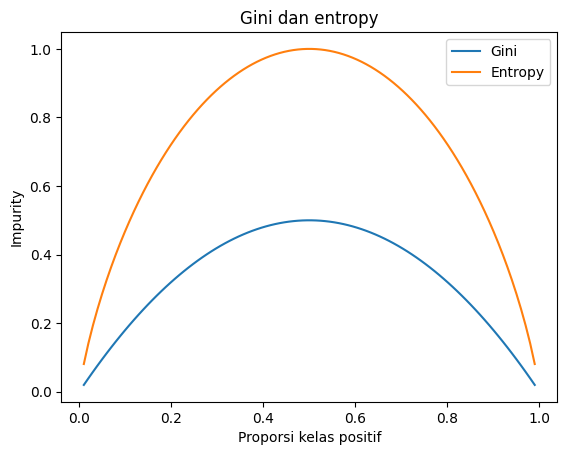

In [32]:
proportions=np.linspace(.01,.99,100)
gini=2*proportions*(1-proportions)
entropy=-(proportions*np.log2(proportions)+(1-proportions)*np.log2(1-proportions))
plt.plot(proportions,gini,label='Gini');plt.plot(proportions,entropy,label='Entropy')
plt.xlabel('Proporsi kelas positif');plt.ylabel('Impurity');plt.title('Gini dan entropy');plt.legend();plt.show()

**Interpretasi hasil:** Kedua kurva bernilai rendah pada node hampir murni dan mencapai puncaknya saat komposisi kelas seimbang. Skala Gini dan entropy berbeda sehingga tinggi kurva tidak dapat dipakai untuk menyimpulkan satu metode selalu lebih unggul.

### 9. Overfitting dan Pembatasan Kedalaman Pohon

Pohon yang sangat dalam dapat menghafal detail spesifik data latih. Ini biasanya memperbesar selisih skor pelatihan dan pengujian. Membatasi kedalaman atau ukuran minimum leaf membantu mengontrol kompleksitas dan menghasilkan aturan yang lebih stabil.

In [33]:
for depth in [2,3,5,None]:
 t=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
 print(f'depth={depth}: train={t.score(X_train,y_train):.3f} | test={t.score(X_test,y_test):.3f}')

depth=2: train=0.958 | test=0.909
depth=3: train=0.977 | test=0.944
depth=5: train=0.995 | test=0.937
depth=None: train=1.000 | test=0.923


**Interpretasi hasil:** Nilai akurasi latih yang sangat tinggi tidak otomatis menunjukkan generalisasi yang baik. Penurunan atau stagnasi nilai uji saat kedalaman ditambah merupakan tanda bahwa model semakin kompleks tanpa manfaat nyata di luar data latih.

### 10. Regression Tree: Prediksi Nilai Kontinu

Pohon keputusan juga dapat memprediksi target numerik. Setiap daun menghasilkan perkiraan nilai kontinu, biasanya berdasarkan rata-rata target pada observasi pelatihan yang masuk ke daun itu. Karena output konstan di tiap region, bentuk prediksinya menyerupai anak tangga dan tidak melakukan ekstrapolasi linear seperti regresi biasa.

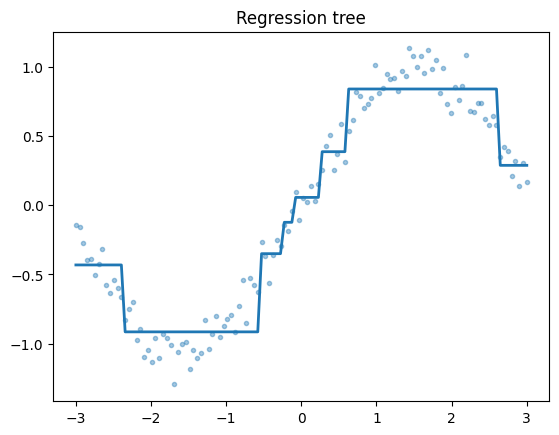

In [34]:
from sklearn.tree import DecisionTreeRegressor
xx=np.linspace(-3,3,120).reshape(-1,1)
yy=np.sin(xx[:,0])+np.random.default_rng(7).normal(0,.12,len(xx))
tr=DecisionTreeRegressor(max_depth=3,random_state=7).fit(xx,yy)
plt.scatter(xx[:,0],yy,s=9,alpha=.4);plt.plot(xx[:,0],tr.predict(xx),linewidth=2)
plt.title('Regression tree');plt.show()

**Interpretasi hasil:** Garis prediksi bertingkat muncul karena observasi dalam satu leaf memperoleh prediksi sama. Model dapat mempelajari hubungan nonlinier, tetapi kedalaman rendah dapat kehilangan detail dan kedalaman berlebih berisiko menyesuaikan noise.

### 11. Bootstrap Sampling dalam Bagging

Bagging membangun banyak model dari sampel bootstrap: dataset pelatihan disampling secara acak dengan pengembalian. Setiap model menerima variasi observasi yang berbeda, lalu prediksinya digabung. Penggabungan tersebut bertujuan mengurangi varians prediksi yang tinggi pada model seperti decision tree.

In [35]:
rng_boot=np.random.default_rng(27)
a=np.arange(12)
for seed in range(3):
 chosen=rng_boot.choice(a,size=len(a),replace=True)
 print('Bootstrap',seed+1,':',chosen,'| unique:',len(np.unique(chosen)))

Bootstrap 1 : [ 0  8  2  3 11  1  7  3  5 11  2  9] | unique: 9
Bootstrap 2 : [ 8  0 10  2  3  3 11 11  3  4  7  2] | unique: 8
Bootstrap 3 : [ 4 10  0 10  1  3  3  4  5  9  7  3] | unique: 8


**Interpretasi hasil:** Dalam satu bootstrap, sebagian observasi muncul beberapa kali dan sebagian tidak muncul sama sekali. Perbedaan sampel ini membuat model dasar tidak identik, sehingga penggabungan hasilnya dapat lebih stabil daripada satu pohon.

### 12. Out-of-Bag Evaluation pada Random Forest

Karena setiap pohon menggunakan bootstrap, sejumlah observasi tidak terambil untuk melatih pohon tersebut. Observasi yang tertinggal ini disebut out-of-bag (OOB) dan dapat digunakan untuk memperkirakan kemampuan generalisasi tanpa membuat set validasi baru. OOB bukan pengganti universal untuk test set independen, tetapi berguna sebagai diagnostik.

In [36]:
from sklearn.ensemble import RandomForestClassifier
rf_oob=RandomForestClassifier(n_estimators=160,oob_score=True,random_state=42,n_jobs=-1)
rf_oob.fit(X_train,y_train)
print('OOB score:',round(rf_oob.oob_score_,3))
print('Test score:',round(rf_oob.score(X_test,y_test),3))

OOB score: 0.962
Test score: 0.958


**Interpretasi hasil:** Kesamaan kasar antara skor OOB dan test mendukung bahwa perkiraan validasi tidak terlalu jauh dari performa di data baru. Perbedaan tetap wajar karena metode sampling dan ukuran data yang digunakan berbeda.

### 13. Permutation Importance vs Impurity Importance

Random forest menyediakan pentingnya fitur berbasis penurunan impurity, tetapi ukuran tersebut memiliki bias tertentu dan tidak langsung menjelaskan manfaat prediktif pada data yang belum dilihat. Permutation importance mengacak satu fitur pada data evaluasi dan mengukur penurunan performa. Pendekatan ini lebih dekat ke pertanyaan tentang kegunaan fitur bagi prediksi model terlatih.

Metrik yang dipakai untuk mengukur penurunan performa adalah log loss, bukan akurasi. Data uji hanya berisi 143 observasi sehingga akurasi berubah dalam langkah yang sangat kasar dan sebagian besar fitur tampak memiliki penurunan nol; peringkat seperti itu tidak bermakna. Log loss memakai probabilitas sehingga perubahan kecil pun terukur. Pengacakan diulang 30 kali agar rata-rata dan simpangan bakunya stabil.

In [37]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(rf_oob, X_test, y_test, scoring='neg_log_loss', n_repeats=30, random_state=42, n_jobs=-1)
comparison = pd.DataFrame({'feature': X.columns, 'impurity': rf_oob.feature_importances_,
                           'permutation_mean': pi.importances_mean, 'permutation_std': pi.importances_std})
comparison['rank_impurity'] = comparison.impurity.rank(ascending=False, method='first').astype(int)
comparison['rank_permutation'] = comparison.permutation_mean.rank(ascending=False, method='first').astype(int)
print(comparison.sort_values('permutation_mean', ascending=False, kind='stable').head(8).round(4).to_string(index=False))

             feature  impurity  permutation_mean  permutation_std  rank_impurity  rank_permutation
          worst area    0.1427            0.0848           0.0067              1                 1
     worst perimeter    0.1413            0.0813           0.0067              2                 2
worst concave points    0.1090            0.0547           0.0086              3                 3
        worst radius    0.0821            0.0510           0.0037              5                 4
 mean concave points    0.1002            0.0442           0.0057              4                 5
          area error    0.0277            0.0288           0.0030             10                 6
           mean area    0.0405            0.0268           0.0021              9                 7
      mean concavity    0.0470            0.0246           0.0032              8                 8


**Interpretasi hasil:** Tiga fitur teratas menurut permutation importance, yaitu `worst area` (0.0848), `worst perimeter` (0.0813), dan `worst concave points` (0.0547), sama dengan tiga teratas menurut impurity importance. Hanya skalanya yang berbeda: impurity importance berjumlah satu di seluruh fitur, sedangkan permutation importance adalah kenaikan log loss ketika fitur diacak. Simpangan baku (0.002 sampai 0.009) jauh lebih kecil daripada nilainya, sehingga peringkat atas tergolong stabil.

Perbedaan muncul di bawahnya. `area error` berada di peringkat 10 menurut impurity tetapi peringkat 6 menurut permutation, dan `mean area` naik dari peringkat 9 ke 7. Fitur radius, perimeter, dan area saling berkorelasi sangat tinggi sehingga pentingnya terbagi di antara mereka dan peringkat relatifnya mudah bergeser. Keduanya sebaiknya dibaca sebagai petunjuk eksplorasi, bukan bukti sebab-akibat.

### 14. AdaBoost dan Sequential Learning

Berbeda dari bagging yang melatih banyak model relatif independen, boosting menyusun model secara berurutan agar model berikutnya berfokus pada kesalahan tahap sebelumnya. AdaBoost meningkatkan bobot observasi yang sulit diklasifikasi, sementara varian gradient boosting bekerja dengan memperbaiki kesalahan melalui fungsi kerugian.

In [38]:
from sklearn.ensemble import AdaBoostClassifier
ada=AdaBoostClassifier(n_estimators=80,learning_rate=.5,random_state=42).fit(X_train,y_train)
print('AdaBoost train:',round(ada.score(X_train,y_train),3))
print('AdaBoost test:',round(ada.score(X_test,y_test),3))

AdaBoost train: 1.0
AdaBoost test: 0.965


**Interpretasi hasil:** Hasil AdaBoost dapat dibandingkan dengan random forest pada data uji yang sama. Skor yang lebih tinggi belum otomatis membuktikan model selalu lebih bagus; kompleksitas, kestabilan, dan biaya komputasi juga penting.

### 15. Gradient Boosting: Learning Rate dan Banyaknya Tree

Gradient boosting membangun model baru berdasarkan arah pengurangan loss dari ensemble sebelumnya. Learning rate mengatur seberapa besar kontribusi setiap pohon tambahan. Learning rate kecil sering perlu lebih banyak pohon, sedangkan learning rate tinggi dapat menimbulkan penyesuaian terlalu agresif pada data latih.

In [39]:
from sklearn.ensemble import GradientBoostingClassifier
for lr,n_est in [(0.05,70),(0.1,70),(0.1,140)]:
 gb=GradientBoostingClassifier(learning_rate=lr,n_estimators=n_est,max_depth=2,random_state=42).fit(X_train,y_train)
 print(f'lr={lr} trees={n_est}: train={gb.score(X_train,y_train):.3f} test={gb.score(X_test,y_test):.3f}')

lr=0.05 trees=70: train=0.993 test=0.951


lr=0.1 trees=70: train=1.000 test=0.944


lr=0.1 trees=140: train=1.000 test=0.951


**Interpretasi hasil:** Variasi learning rate dan jumlah estimator mengubah kompromi bias dan varians. Skor terbaik pada satu test set sebaiknya tidak digunakan langsung untuk tuning; pilihan parameter ideal ditentukan melalui cross-validation pada data pelatihan.

### 16. Hyperparameter Tuning dengan Grid Search

Parameter model seperti jumlah tetangga, kedalaman pohon, dan batas minimal sampel di leaf tidak dipelajari otomatis melalui proses fitting biasa. Grid search menguji kombinasi parameter melalui validasi silang dan kemudian memilih pengaturan dengan skor rata-rata terbaik. Semua pilihan model di sini menggunakan hanya data pelatihan.

In [40]:
from sklearn.model_selection import GridSearchCV
param={'max_depth':[2,3,4,5],'min_samples_leaf':[1,3,8]}
grid_tree=GridSearchCV(DecisionTreeClassifier(random_state=42),param,cv=3,scoring='balanced_accuracy',n_jobs=-1)
grid_tree.fit(X_train,y_train)
best_tree=grid_tree.best_estimator_
print('Best parameters:',grid_tree.best_params_)
print('Best CV balanced accuracy:',round(grid_tree.best_score_,3))
print('Test accuracy:',round(accuracy_score(y_test,best_tree.predict(X_test)),3))
print('Test balanced accuracy:',round(grid_tree.score(X_test,y_test),3))

Best parameters: {'max_depth': 5, 'min_samples_leaf': 8}
Best CV balanced accuracy: 0.922
Test accuracy: 0.951
Test balanced accuracy: 0.946


**Interpretasi hasil:** Validasi silang digunakan untuk membandingkan parameter tanpa mengambil keputusan berdasarkan set uji. Kombinasi terbaik adalah `max_depth=5` dan `min_samples_leaf=8` dengan balanced accuracy validasi silang 0.922. Setelah konfigurasi terbaik ditemukan, evaluasi akhir pada data uji memberi gambaran performa pada observasi yang belum dipakai untuk pemilihan parameter: akurasi 0.951 dan balanced accuracy 0.946.

Perhatikan bahwa `grid_tree.score()` memakai metrik yang ditentukan pada `scoring` (di sini balanced accuracy), bukan akurasi biasa. Karena itu akurasi dihitung terpisah dari `best_estimator_` agar label setiap angka sesuai dengan metriknya.